# Tugas Lab 2 - Klasterisasi Dataset Nyata dengan HDBSCAN
1. Memilih salah satu dataset nyata dari `sklearn.datasets` (Iris dataset).
2. Melakukan clustering dengan HDBSCAN.
3. Melaporkan hasil: jumlah cluster yang terbentuk, banyaknya noise, dan visualisasi dengan PCA 2D.
4. Membuat analisis singkat mengenai kesesuaian hasil clustering HDBSCAN dengan label asli dataset.


## Langkah 1 - Import Library
Import modul yang diperlukan.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score
import hdbscan


## Langkah 2 - Load Dataset
Memuat dataset nyata Iris dari `sklearn.datasets`.


In [2]:
iris = load_iris()
X = iris.data
y_true = iris.target
target_names = iris.target_names

print("Dimensi dataset:", X.shape)
print("Nama fitur:", iris.feature_names)
print("Target classes:", target_names)


Dimensi dataset: (150, 4)
Nama fitur: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target classes: ['setosa' 'versicolor' 'virginica']


## Langkah 3 - Preprocessing
Melakukan standardisasi fitur dengan `StandardScaler`.


In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


## Langkah 4 - Pemodelan Klasterisasi dengan HDBSCAN
Melakukan clustering menggunakan algoritma HDBSCAN.


In [4]:
clusterer = hdbscan.HDBSCAN(min_cluster_size=10, min_samples=5)
labels = clusterer.fit_predict(X_scaled)


## Langkah 5 - Laporan Hasil Clustering
Melaporkan jumlah cluster yang terbentuk dan banyaknya noise.


In [5]:
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)

print("=" * 40)
print(f"Jumlah cluster yang terbentuk : {n_clusters}")
print(f"Banyaknya noise (-1)         : {n_noise}")
print("=" * 40)


Jumlah cluster yang terbentuk : 2
Banyaknya noise (-1)         : 2


## Langkah 6 - Reduksi Dimensi dengan PCA dan Visualisasi
Mereduksi dimensi data menjadi 2 dimensi dengan PCA untuk visualisasi hasil clustering HDBSCAN berdampingan dengan label asli.


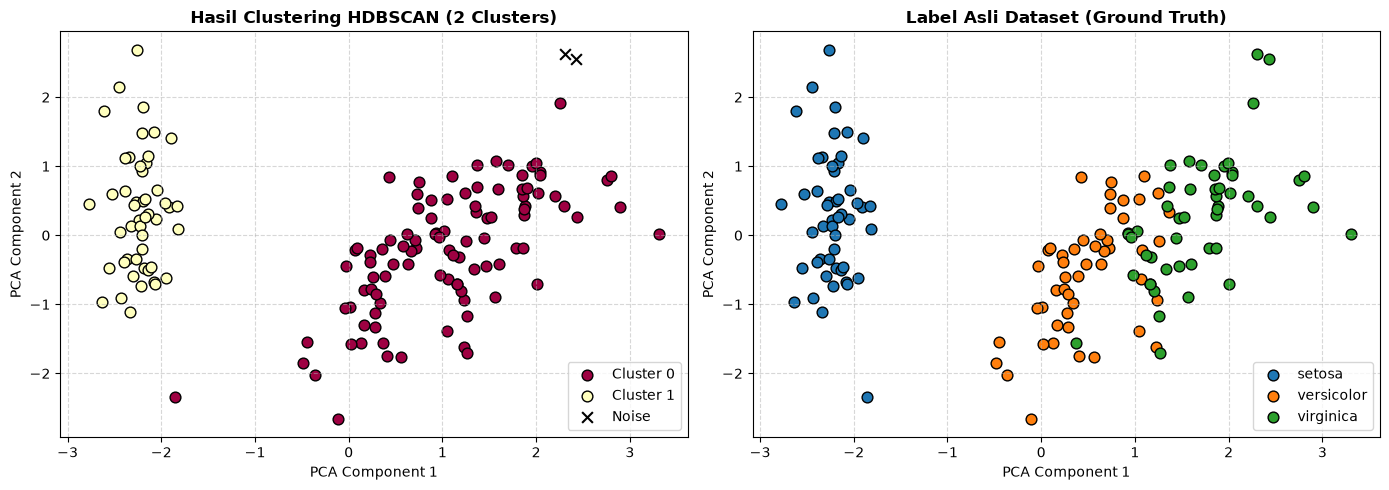

In [6]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot HDBSCAN Clusters
unique_labels = set(labels)
colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
for k, col in zip(unique_labels, colors):
    if k == -1:
        col = [0, 0, 0, 1]  # Hitam untuk noise
    class_member_mask = (labels == k)
    xy = X_pca[class_member_mask]
    axes[0].scatter(xy[:, 0], xy[:, 1], color=tuple(col),
                    marker='x' if k == -1 else 'o',
                    s=60, edgecolors='k' if k != -1 else None,
                    label=f'Cluster {k}' if k != -1 else 'Noise')
axes[0].set_title(f'Hasil Clustering HDBSCAN ({n_clusters} Clusters)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('PCA Component 1')
axes[0].set_ylabel('PCA Component 2')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot Ground Truth
for i, name in enumerate(target_names):
    axes[1].scatter(X_pca[y_true == i, 0], X_pca[y_true == i, 1],
                    label=name, s=60, edgecolors='k')
axes[1].set_title('Label Asli Dataset (Ground Truth)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('PCA Component 1')
axes[1].set_ylabel('PCA Component 2')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


## Langkah 7 - Evaluasi dan Analisis Hasil Clustering
Menghitung metrik evaluasi Silhouette Score dan Davies-Bouldin Index, serta analisis kesesuaian cluster dengan label asli.


In [7]:
mask = (labels != -1)
sil = silhouette_score(X_scaled[mask], labels[mask])
dbi = davies_bouldin_score(X_scaled[mask], labels[mask])
print(f"Silhouette Score (core points)    : {sil:.4f}")
print(f"Davies-Bouldin Index (core points): {dbi:.4f}")


Silhouette Score (core points)    : 0.5853
Davies-Bouldin Index (core points): 0.5833


### Analisis Singkat:
**Apakah hasil clustering HDBSCAN sesuai dengan label asli dataset tersebut?**

1. **Jumlah Cluster yang Terbentuk:**
   HDBSCAN menghasilkan **2 cluster**, sedangkan label asli dataset Iris memiliki 3 kelas (*Setosa*, *Versicolor*, *Virginica*).
2. **Kesesuaian dengan Struktur Data:**
   - Kelas *Setosa* berhasil dipisahkan secara sempurna ke dalam satu cluster tersendiri karena letaknya terpisah jauh secara geometris dan densitas dari kelas lainnya.
   - Kelas *Versicolor* dan *Virginica* digabungkan ke dalam satu cluster yang sama. Hal ini terjadi karena dalam ruang fitur biologis Iris, sebaran kedua kelas tersebut saling tumpang tindih (*overlapping*) dan memiliki kepadatan spasial yang kontinu, sehingga HDBSCAN yang berbasis kepadatan (*density-based*) mengidentifikasinya sebagai satu kesatuan cluster.
3. **Kesimpulan:**
   Hasil clustering HDBSCAN mencerminkan struktur kepadatan alami (*natural density distribution*) dari dataset, bukan memaksakan partisi seperti pada algoritma berbasis jarak sentroid (K-Means).
